In [1]:

!pip install neurokit2==0.2.13 wfdb==4.3.1

import time
import sys
import numpy as np
import neurokit2 as nk
import wfdb
import wfdb.processing

from scipy.signal import find_peaks

baslangic_zamani = time.perf_counter()

fs = 500

tohumlar = {
    60: [3, 4, 5, 6, 7],
    80: [1, 2, 3, 5, 6],
    100: [1, 2, 3, 4, 5]
}

print("Başlangıç ayarları hazır.")
print("Örnekleme frekansı:", fs, "Hz")
print("Başlangıç tohumları:", tohumlar)


Başlangıç ayarları hazır.
Örnekleme frekansı: 500 Hz
Başlangıç tohumları: {60: [3, 4, 5, 6, 7], 80: [1, 2, 3, 5, 6], 100: [1, 2, 3, 4, 5]}


In [2]:

kayit = {}
kullanilan_tohumlar = {}

yedek_tohumlar = {
    60: [8, 9, 10, 11, 12],
    80: [7, 8, 9, 10, 11],
    100: [6, 7, 8, 9, 10]
}

def hr5(R):
    sonuc = []
    for bas in [2, 12, 22, 32, 42]:
        secilen = R[(R / fs >= bas) & (R / fs <= bas + 10)]
        if len(secilen) < 2:
            sonuc.append(0)
        else:
            sure = (secilen[-1] - secilen[0]) / fs
            sonuc.append(60 * (len(secilen) - 1) / sure)
    return np.array(sonuc)

for HR, ilk_tohumlar in tohumlar.items():
    kabul_edilen = []
    adaylar = ilk_tohumlar + yedek_tohumlar[HR]

    for tohum in adaylar:
        if len(kabul_edilen) == 5:
            break

        c = nk.ecg_simulate(
            duration=60,
            sampling_rate=fs,
            noise=0,
            heart_rate=HR,
            heart_rate_std=1,
            method="ecgsyn",
            random_state=tohum
        )

        R = find_peaks(
            c,
            height=0.5 * np.percentile(c, 99),
            distance=125
        )[0]

        RR = np.diff(R)
        oran = np.max(RR) / np.min(RR) if len(RR) else np.inf

        if oran <= 1.5 and len(R) >= 2:
            A_R = np.median(c[R])
            kayit[(HR, tohum)] = (c, R, A_R)
            kabul_edilen.append(tohum)
            print(f"KABUL: HR={HR}, tohum={tohum}, RR oranı={oran:.3f}")
        else:
            print(f"RED: HR={HR}, tohum={tohum}, RR oranı={oran:.3f}")

    kullanilan_tohumlar[HR] = kabul_edilen

    if len(kabul_edilen) != 5:
        raise RuntimeError(f"HR={HR} için 5 geçerli kayıt bulunamadı.")

print("\nToplam kayıt:", len(kayit))
print("Kullanılan tohumlar:", kullanilan_tohumlar)



KABUL: HR=60, tohum=3, RR oranı=1.068
KABUL: HR=60, tohum=4, RR oranı=1.077
KABUL: HR=60, tohum=5, RR oranı=1.077
RED: HR=60, tohum=6, RR oranı=3.801
KABUL: HR=60, tohum=7, RR oranı=1.074
KABUL: HR=60, tohum=8, RR oranı=1.070
KABUL: HR=80, tohum=1, RR oranı=1.044
KABUL: HR=80, tohum=2, RR oranı=1.052
KABUL: HR=80, tohum=3, RR oranı=1.049
KABUL: HR=80, tohum=5, RR oranı=1.058
KABUL: HR=80, tohum=6, RR oranı=1.060
KABUL: HR=100, tohum=1, RR oranı=1.041
KABUL: HR=100, tohum=2, RR oranı=1.048
KABUL: HR=100, tohum=3, RR oranı=1.037
KABUL: HR=100, tohum=4, RR oranı=1.044
KABUL: HR=100, tohum=5, RR oranı=1.048

Toplam kayıt: 15
Kullanılan tohumlar: {60: [3, 4, 5, 7, 8], 80: [1, 2, 3, 5, 6], 100: [1, 2, 3, 4, 5]}


In [3]:

print("HR | Tohum | R sayısı | RR oranı | 5 pencere HR")

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):
    RR = np.diff(R)
    oran = np.max(RR) / np.min(RR)
    pencere_hr = hr5(R)

    print(
        f"{HR:3d} | {tohum:5d} | {len(R):8d} | "
        f"{oran:8.3f} | {np.round(pencere_hr, 2)}"
    )

print("\nToplam kayıt:", len(kayit))


HR | Tohum | R sayısı | RR oranı | 5 pencere HR
 60 |     3 |       59 |    1.068 | [60.15 60.19 59.91 60.23 60.11]
 60 |     4 |       60 |    1.077 | [59.99 60.04 60.03 60.3  60.12]
 60 |     5 |       60 |    1.077 | [59.91 59.99 60.01 59.88 60.08]
 60 |     7 |       60 |    1.074 | [60.03 59.93 59.93 60.02 60.11]
 60 |     8 |       60 |    1.070 | [59.88 60.24 60.12 60.04 60.07]
 80 |     1 |       80 |    1.044 | [80.15 79.96 80.05 80.05 80.18]
 80 |     2 |       80 |    1.052 | [80.12 79.84 80.04 80.16 79.98]
 80 |     3 |       80 |    1.049 | [80.18 80.18 79.79 80.16 80.09]
 80 |     5 |       80 |    1.058 | [79.8  79.91 80.07 79.91 80.08]
 80 |     6 |       80 |    1.060 | [80.18 79.89 79.98 79.95 80.02]
100 |     1 |      100 |    1.041 | [100.17  99.98 100.06 100.   100.18]
100 |     2 |      100 |    1.048 | [100.08  99.84 100.1  100.1   99.96]
100 |     3 |      100 |    1.037 | [100.19 100.17  99.77 100.13 100.04]
100 |     4 |      100 |    1.044 | [ 99.98 100.04  9

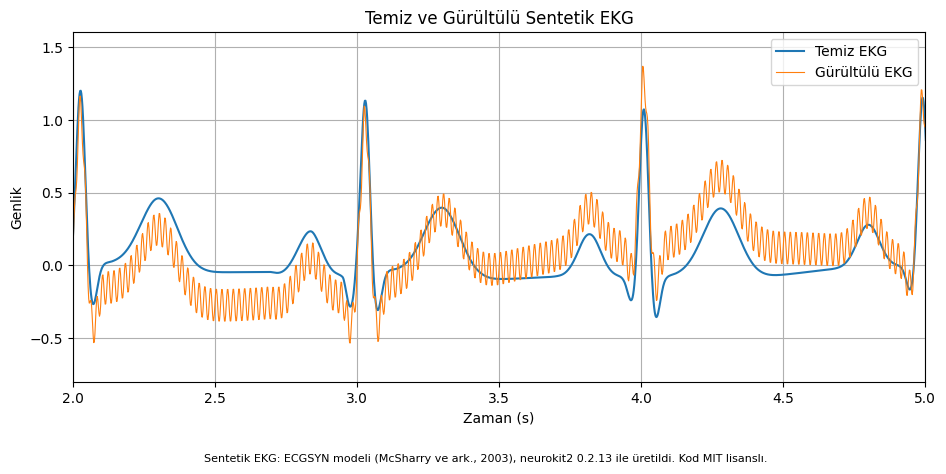

Kaydedildi: sekil1_kesit.png


In [4]:

import matplotlib.pyplot as plt

# Örnek kayıt
HR, tohum = 60, 3
c, R, A_R = kayit[(HR, tohum)]

# Zaman ekseni
t = np.arange(len(c)) / fs

# Parazitler
parazit_50hz = 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
taban_kaymasi = 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)

# Gürültülü EKG
x = c + parazit_50hz + taban_kaymasi

# Şekil
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(t, c, label="Temiz EKG", linewidth=1.5)
ax.plot(t, x, label="Gürültülü EKG", linewidth=0.8)

ax.set_xlim(2, 5)
ax.set_xlabel("Zaman (s)")
ax.set_ylabel("Genlik")
ax.set_title("Temiz ve Gürültülü Sentetik EKG")
ax.grid(True)
ax.legend()

# Kaynak ve lisans notu
not_metni = (
    "Sentetik EKG: ECGSYN modeli (McSharry ve ark., 2003), "
    "neurokit2 0.2.13 ile üretildi. Kod MIT lisanslı."
)

fig.text(
    0.5, 0.02, not_metni,
    ha="center", fontsize=8
)

fig.subplots_adjust(bottom=0.18)

# PNG olarak kaydet
fig.savefig("sekil1_kesit.png", dpi=300, bbox_inches="tight")

plt.show()

print("Kaydedildi: sekil1_kesit.png")


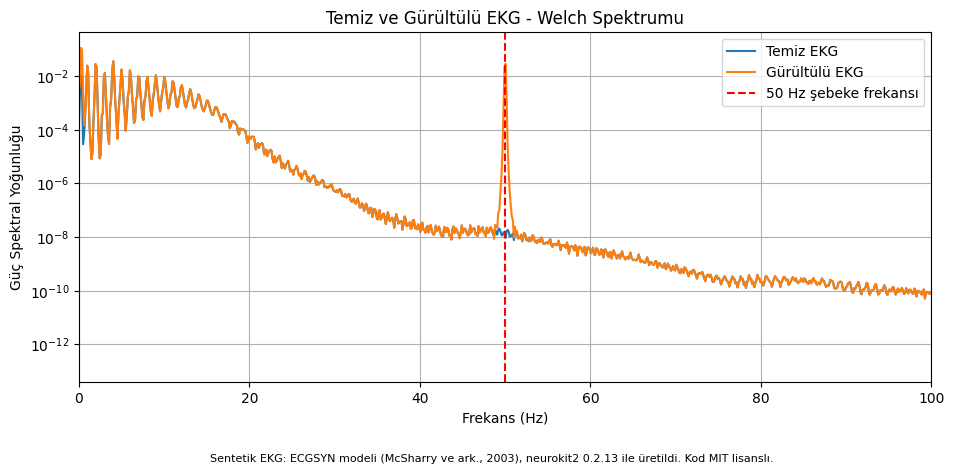

Kaydedildi: sekil2_welch.png


In [5]:

from scipy.signal import welch

# Temiz ve gürültülü EKG spektrumları
f, P_temiz = welch(c, fs=fs, nperseg=4096)
_, P_gurultulu = welch(x, fs=fs, nperseg=4096)

# Grafik
fig, ax = plt.subplots(figsize=(11, 5))

ax.semilogy(f, P_temiz, label="Temiz EKG")
ax.semilogy(f, P_gurultulu, label="Gürültülü EKG")

ax.axvline(
    50,
    color="red",
    linestyle="--",
    label="50 Hz şebeke frekansı"
)

ax.set_xlim(0, 100)
ax.set_xlabel("Frekans (Hz)")
ax.set_ylabel("Güç Spektral Yoğunluğu")
ax.set_title("Temiz ve Gürültülü EKG - Welch Spektrumu")
ax.grid(True)
ax.legend()

# Kaynak ve lisans notu
not_metni = (
    "Sentetik EKG: ECGSYN modeli (McSharry ve ark., 2003), "
    "neurokit2 0.2.13 ile üretildi. Kod MIT lisanslı."
)

fig.text(0.5, 0.02, not_metni, ha="center", fontsize=8)
fig.subplots_adjust(bottom=0.18)

# Şekli kaydet
fig.savefig("sekil2_welch.png", dpi=300, bbox_inches="tight")

plt.show()

print("Kaydedildi: sekil2_welch.png")


In [6]:

import pandas as pd
from scipy.ndimage import uniform_filter1d

sonuclar = []

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):

    t = np.arange(len(c)) / fs

    x = (
        c
        + 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
        + 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)
    )

    # D1: Genlik eşiği
    R1 = find_peaks(
        x,
        height=0.5 * np.percentile(x, 99),
        distance=125
    )[0]

    # D2: Türev enerjisi
    turev = np.diff(x, prepend=x[0])
    enerji = turev ** 2
    yumusak = uniform_filter1d(enerji, size=40)

    adaylar = find_peaks(
        yumusak,
        height=0.3 * np.max(yumusak),
        distance=125
    )[0]

    R2 = []

    for p in adaylar:
        bas = max(0, p - 50)
        son = min(len(x), p + 51)
        R2.append(bas + np.argmax(x[bas:son]))

    R2 = np.unique(R2)

    # Kalp hızı hataları
    referans = hr5(R)

    hata_D1 = np.mean(np.abs(hr5(R1) - referans))
    hata_D2 = np.mean(np.abs(hr5(R2) - referans))

    sonuclar.append({
        "HR": HR,
        "Tohum": tohum,
        "D1_MAE_bpm": hata_D1,
        "D2_MAE_bpm": hata_D2
    })

tablo = pd.DataFrame(sonuclar)

tablo.to_csv("tablo_asama2.csv", index=False)

print(tablo.to_string(index=False))
print("\nKaydedildi: tablo_asama2.csv")
print("Kayıt sayısı:", len(tablo))


 HR  Tohum  D1_MAE_bpm  D2_MAE_bpm
 60      3   30.278949    0.021574
 60      4   30.964451    0.020619
 60      5   32.003151    0.040092
 60      7   28.992395    0.029386
 60      8   32.052463    0.026750
 80      1   27.066289    0.037225
 80      2   27.259638    0.020020
 80      3   21.772948    0.030994
 80      5   34.220903    0.049465
 80      6   24.105352    0.033382
100      1    0.030276    0.030276
100      2    0.055339    0.055339
100      3    0.023645    0.023645
100      4    0.016942    0.016942
100      5    0.037201    0.037201

Kaydedildi: tablo_asama2.csv
Kayıt sayısı: 15


In [7]:

from scipy.signal import iirnotch, filtfilt

b, a = iirnotch(w0=50, Q=30, fs=fs)

filtreli_sonuclar = []

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):

    t = np.arange(len(c)) / fs

    x = (
        c
        + 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
        + 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)
    )

    # 50 Hz notch filtresi
    xf = filtfilt(b, a, x)

    # D1: Filtreli sinyal
    R1 = find_peaks(
        xf,
        height=0.5 * np.percentile(xf, 99),
        distance=125
    )[0]

    # D2: Filtreli sinyal
    turev = np.diff(xf, prepend=xf[0])
    enerji = turev ** 2
    yumusak = uniform_filter1d(enerji, size=40)

    adaylar = find_peaks(
        yumusak,
        height=0.3 * np.max(yumusak),
        distance=125
    )[0]

    R2 = []

    for p in adaylar:
        bas = max(0, p - 50)
        son = min(len(xf), p + 51)
        R2.append(bas + np.argmax(xf[bas:son]))

    R2 = np.unique(R2)

    # Kalp hızı hataları
    referans = hr5(R)

    hata_D1 = np.mean(np.abs(hr5(R1) - referans))
    hata_D2 = np.mean(np.abs(hr5(R2) - referans))

    filtreli_sonuclar.append({
        "HR": HR,
        "Tohum": tohum,
        "D1_MAE_bpm": hata_D1,
        "D2_MAE_bpm": hata_D2
    })

tablo_filtreli = pd.DataFrame(filtreli_sonuclar)

tablo_filtreli.to_csv(
    "tablo_asama2_filtreli.csv",
    index=False
)

print(tablo_filtreli.to_string(index=False))
print("\nKaydedildi: tablo_asama2_filtreli.csv")
print("Kayıt sayısı:", len(tablo_filtreli))


 HR  Tohum  D1_MAE_bpm  D2_MAE_bpm
 60      3   19.735475    0.000000
 60      4   20.499038    0.000000
 60      5   18.676263    0.000000
 60      7   23.402513    0.000000
 60      8   17.356537    0.000000
 80      1    0.000000    0.000000
 80      2    0.000000    0.000000
 80      3    0.000000    0.000000
 80      5    0.000000    0.000000
 80      6    0.000000    0.000000
100      1    0.000000    0.000000
100      2    0.000000    0.000000
100      3    0.000000    0.000000
100      4    0.000000    0.000000
100      5    0.004171    0.004171

Kaydedildi: tablo_asama2_filtreli.csv
Kayıt sayısı: 15


In [8]:

HR, tohum = 60, 8

c = nk.ecg_simulate(
    duration=60,
    sampling_rate=fs,
    noise=0,
    heart_rate=HR,
    heart_rate_std=1,
    method="ecgsyn",
    random_state=tohum
)

R = find_peaks(
    c,
    height=0.5 * np.percentile(c, 99),
    distance=125
)[0]

RR = np.diff(R)
oran = np.max(RR) / np.min(RR) if len(RR) else np.inf
A_R = np.median(c[R]) if len(R) else np.nan

print(f"Hedef HR={HR} bpm, tohum={tohum}")
print(f"R tepesi sayısı: {len(R)}")
print(f"max(RR)/min(RR): {oran:.3f}")
print(f"5 pencerenin HR değerleri: {np.round(hr5(R), 2)}")

if oran <= 1.5 and len(R) > 1:
    kayit.pop((60, 6), None)
    kayit[(HR, tohum)] = (c, R, A_R)
    print("Kayıt kabul edildi; tohum 6 yerine tohum 8 kullanılıyor.")
else:
    print("Kayıt koşulu sağlamadı; çıktıyı incelemeliyiz.")


Hedef HR=60 bpm, tohum=8
R tepesi sayısı: 60
max(RR)/min(RR): 1.070
5 pencerenin HR değerleri: [59.88 60.24 60.12 60.04 60.07]
Kayıt kabul edildi; tohum 6 yerine tohum 8 kullanılıyor.


In [9]:

print("Kayıt sayısı:", len(kayit))
print("\nHedef HR | Tohum | R tepesi | RR oranı | 5 pencere HR")

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):
    RR = np.diff(R)
    oran = np.max(RR) / np.min(RR) if len(RR) else np.inf

    print(
        f"{HR:8d} | {tohum:5d} | {len(R):8d} | "
        f"{oran:8.3f} | {np.round(hr5(R), 2)}"
    )


Kayıt sayısı: 15

Hedef HR | Tohum | R tepesi | RR oranı | 5 pencere HR
      60 |     3 |       59 |    1.068 | [60.15 60.19 59.91 60.23 60.11]
      60 |     4 |       60 |    1.077 | [59.99 60.04 60.03 60.3  60.12]
      60 |     5 |       60 |    1.077 | [59.91 59.99 60.01 59.88 60.08]
      60 |     7 |       60 |    1.074 | [60.03 59.93 59.93 60.02 60.11]
      60 |     8 |       60 |    1.070 | [59.88 60.24 60.12 60.04 60.07]
      80 |     1 |       80 |    1.044 | [80.15 79.96 80.05 80.05 80.18]
      80 |     2 |       80 |    1.052 | [80.12 79.84 80.04 80.16 79.98]
      80 |     3 |       80 |    1.049 | [80.18 80.18 79.79 80.16 80.09]
      80 |     5 |       80 |    1.058 | [79.8  79.91 80.07 79.91 80.08]
      80 |     6 |       80 |    1.060 | [80.18 79.89 79.98 79.95 80.02]
     100 |     1 |      100 |    1.041 | [100.17  99.98 100.06 100.   100.18]
     100 |     2 |      100 |    1.048 | [100.08  99.84 100.1  100.1   99.96]
     100 |     3 |      100 |    1.037 | [

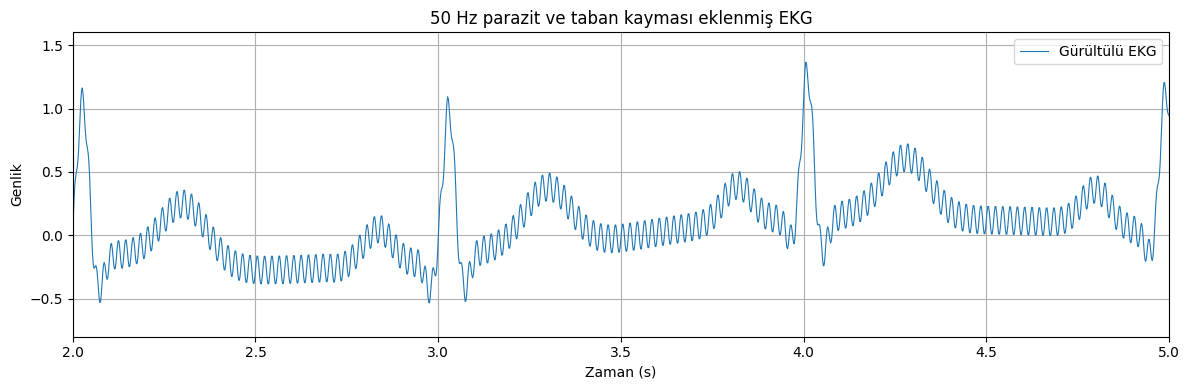

In [10]:

import matplotlib.pyplot as plt

HR, tohum = 60, 3
c, R, A_R = kayit[(HR, tohum)]

t = np.arange(len(c)) / fs

parazit_50hz = 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
taban_kaymasi = 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)

c_gurultulu = c + parazit_50hz + taban_kaymasi

plt.figure(figsize=(12, 4))
plt.plot(t, c_gurultulu, label="Gürültülü EKG", linewidth=0.8)
plt.xlim(2, 5)
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.title("50 Hz parazit ve taban kayması eklenmiş EKG")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



In [11]:

R_D1 = find_peaks(
    c_gurultulu,
    height=0.5 * np.percentile(c_gurultulu, 99),
    distance=125
)[0]

print("Referans R tepesi sayısı:", len(R))
print("D1 tarafından bulunan tepe sayısı:", len(R_D1))
print("Referans HR (5 pencere):", np.round(hr5(R), 2))
print("D1 HR (5 pencere):", np.round(hr5(R_D1), 2))

hata = np.abs(np.array(hr5(R_D1)) - np.array(hr5(R)))

print("Mutlak HR hataları (bpm):", np.round(hata, 2))
print("Ortalama mutlak HR hatası (bpm):", round(np.mean(hata), 3))



Referans R tepesi sayısı: 59
D1 tarafından bulunan tepe sayısı: 90
Referans HR (5 pencere): [60.15 60.19 59.91 60.23 60.11]
D1 HR (5 pencere): [84.25 96.35 94.18 90.36 86.84]
Mutlak HR hataları (bpm): [24.1  36.15 34.27 30.13 26.73]
Ortalama mutlak HR hatası (bpm): 30.279


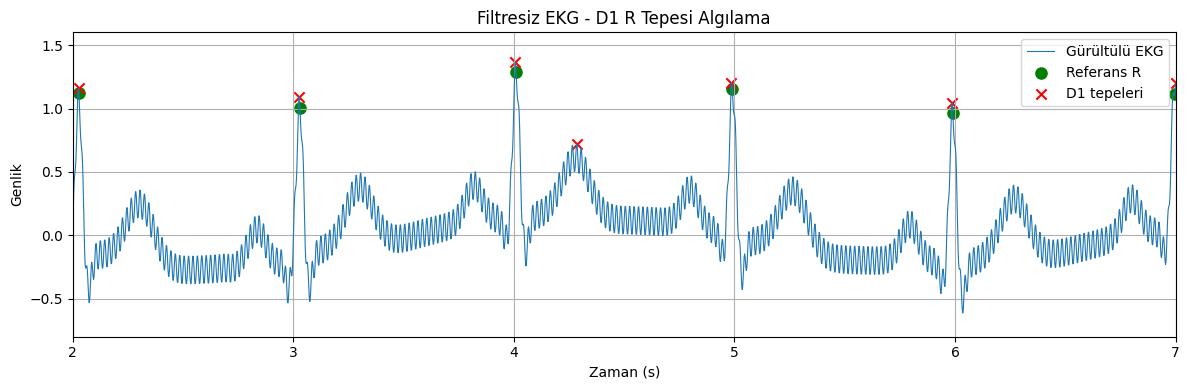

In [12]:

plt.figure(figsize=(12, 4))

plt.plot(
    t, c_gurultulu,
    label="Gürültülü EKG",
    linewidth=0.8
)

plt.scatter(
    t[R],
    c_gurultulu[R],
    color="green",
    marker="o",
    s=65,
    label="Referans R"
)

plt.scatter(
    t[R_D1],
    c_gurultulu[R_D1],
    color="red",
    marker="x",
    s=55,
    label="D1 tepeleri"
)

plt.xlim(2, 7)
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.title("Filtresiz EKG - D1 R Tepesi Algılama")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



In [13]:

from scipy.ndimage import uniform_filter1d

turev = np.diff(c_gurultulu, prepend=c_gurultulu[0])

enerji = turev ** 2

enerji_yumusak = uniform_filter1d(
    enerji,
    size=40
)

adaylar = find_peaks(
    enerji_yumusak,
    height=0.3 * np.max(enerji_yumusak),
    distance=125
)[0]

R_D2 = []

for p in adaylar:
    bas = max(0, p - 50)
    son = min(len(c_gurultulu), p + 51)

    r = bas + np.argmax(c_gurultulu[bas:son])
    R_D2.append(r)

R_D2 = np.unique(R_D2)

hata_D2 = np.abs(
    np.array(hr5(R_D2)) - np.array(hr5(R))
)

print("Referans R tepesi sayısı:", len(R))
print("D2 tarafından bulunan tepe sayısı:", len(R_D2))
print("Referans HR:", np.round(hr5(R), 2))
print("D2 HR:", np.round(hr5(R_D2), 2))
print("Mutlak HR hataları (bpm):", np.round(hata_D2, 2))
print("Ortalama mutlak HR hatası (bpm):", round(np.mean(hata_D2), 3))


Referans R tepesi sayısı: 59
D2 tarafından bulunan tepe sayısı: 61
Referans HR: [60.15 60.19 59.91 60.23 60.11]
D2 HR: [60.13 60.22 59.87 60.24 60.12]
Mutlak HR hataları (bpm): [0.01 0.02 0.04 0.01 0.01]
Ortalama mutlak HR hatası (bpm): 0.022


In [14]:

sonuclar = []

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):

    t = np.arange(len(c)) / fs

    x = (
        c
        + 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
        + 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)
    )

    # D1: Doğrudan genlik eşiği
    R1 = find_peaks(
        x,
        height=0.5 * np.percentile(x, 99),
        distance=125
    )[0]

    # D2: Türev enerjisi
    turev = np.diff(x, prepend=x[0])
    enerji = turev ** 2
    yumusak = uniform_filter1d(enerji, size=40)

    adaylar = find_peaks(
        yumusak,
        height=0.3 * np.max(yumusak),
        distance=125
    )[0]

    R2 = []

    for p in adaylar:
        bas = max(0, p - 50)
        son = min(len(x), p + 51)
        R2.append(bas + np.argmax(x[bas:son]))

    R2 = np.unique(R2)

    # Beş penceredeki mutlak HR hataları
    referans = np.array(hr5(R))
    hata1 = np.abs(np.array(hr5(R1)) - referans)
    hata2 = np.abs(np.array(hr5(R2)) - referans)

    sonuclar.append((HR, tohum, np.mean(hata1), np.mean(hata2)))

sonuclar = np.array(sonuclar)

print("HR | Tohum | D1 MAE | D2 MAE")

for HR, tohum, e1, e2 in sonuclar:
    print(f"{int(HR):3d} | {int(tohum):5d} | {e1:6.3f} | {e2:6.3f}")

print("\n--- 15 KAYITLIK BASELINE ---")
print("D1 ortalama MAE (bpm):", round(np.mean(sonuclar[:, 2]), 3))
print("D2 ortalama MAE (bpm):", round(np.mean(sonuclar[:, 3]), 3))


HR | Tohum | D1 MAE | D2 MAE
 60 |     3 | 30.279 |  0.022
 60 |     4 | 30.964 |  0.021
 60 |     5 | 32.003 |  0.040
 60 |     7 | 28.992 |  0.029
 60 |     8 | 32.052 |  0.027
 80 |     1 | 27.066 |  0.037
 80 |     2 | 27.260 |  0.020
 80 |     3 | 21.773 |  0.031
 80 |     5 | 34.221 |  0.049
 80 |     6 | 24.105 |  0.033
100 |     1 |  0.030 |  0.030
100 |     2 |  0.055 |  0.055
100 |     3 |  0.024 |  0.024
100 |     4 |  0.017 |  0.017
100 |     5 |  0.037 |  0.037

--- 15 KAYITLIK BASELINE ---
D1 ortalama MAE (bpm): 19.259
D2 ortalama MAE (bpm): 0.032


In [15]:

from scipy.signal import iirnotch, filtfilt

# 50 Hz notch filtresi
b, a = iirnotch(w0=50, Q=30, fs=fs)

filtreli_sonuclar = []

for (HR, tohum), (c, R, A_R) in sorted(kayit.items()):

    t = np.arange(len(c)) / fs

    x = (
        c
        + 0.1 * A_R * np.sin(2 * np.pi * 50 * t)
        + 0.2 * A_R * np.sin(2 * np.pi * 0.3 * t)
    )

    # 50 Hz parazitini filtrele
    xf = filtfilt(b, a, x)

    # D1: Filtreli sinyal
    R1 = find_peaks(
        xf,
        height=0.5 * np.percentile(xf, 99),
        distance=125
    )[0]

    # D2: Filtreli sinyal
    turev = np.diff(xf, prepend=xf[0])
    enerji = turev ** 2
    yumusak = uniform_filter1d(enerji, size=40)

    adaylar = find_peaks(
        yumusak,
        height=0.3 * np.max(yumusak),
        distance=125
    )[0]

    R2 = []

    for p in adaylar:
        bas = max(0, p - 50)
        son = min(len(xf), p + 51)
        R2.append(bas + np.argmax(xf[bas:son]))

    R2 = np.unique(R2)

    referans = np.array(hr5(R))

    e1 = np.mean(np.abs(np.array(hr5(R1)) - referans))
    e2 = np.mean(np.abs(np.array(hr5(R2)) - referans))

    filtreli_sonuclar.append((HR, tohum, e1, e2))

filtreli_sonuclar = np.array(filtreli_sonuclar)

print("--- FILTRESIZ BASELINE ---")
print("D1 MAE:", round(np.mean(sonuclar[:, 2]), 3), "bpm")
print("D2 MAE:", round(np.mean(sonuclar[:, 3]), 3), "bpm")

print("\n--- 50 Hz NOTCH FILTRELI ---")
print("D1 MAE:", round(np.mean(filtreli_sonuclar[:, 2]), 3), "bpm")
print("D2 MAE:", round(np.mean(filtreli_sonuclar[:, 3]), 3), "bpm")

print("\n--- KAYIT BAZINDA FILTRELI SONUCLAR ---")
print("HR | Tohum | D1 MAE | D2 MAE")

for HR, tohum, e1, e2 in filtreli_sonuclar:
    print(f"{int(HR):3d} | {int(tohum):5d} | {e1:6.3f} | {e2:6.3f}")


--- FILTRESIZ BASELINE ---
D1 MAE: 19.259 bpm
D2 MAE: 0.032 bpm

--- 50 Hz NOTCH FILTRELI ---
D1 MAE: 6.645 bpm
D2 MAE: 0.0 bpm

--- KAYIT BAZINDA FILTRELI SONUCLAR ---
HR | Tohum | D1 MAE | D2 MAE
 60 |     3 | 19.735 |  0.000
 60 |     4 | 20.499 |  0.000
 60 |     5 | 18.676 |  0.000
 60 |     7 | 23.403 |  0.000
 60 |     8 | 17.357 |  0.000
 80 |     1 |  0.000 |  0.000
 80 |     2 |  0.000 |  0.000
 80 |     3 |  0.000 |  0.000
 80 |     5 |  0.000 |  0.000
 80 |     6 |  0.000 |  0.000
100 |     1 |  0.000 |  0.000
100 |     2 |  0.000 |  0.000
100 |     3 |  0.000 |  0.000
100 |     4 |  0.000 |  0.000
100 |     5 |  0.004 |  0.004


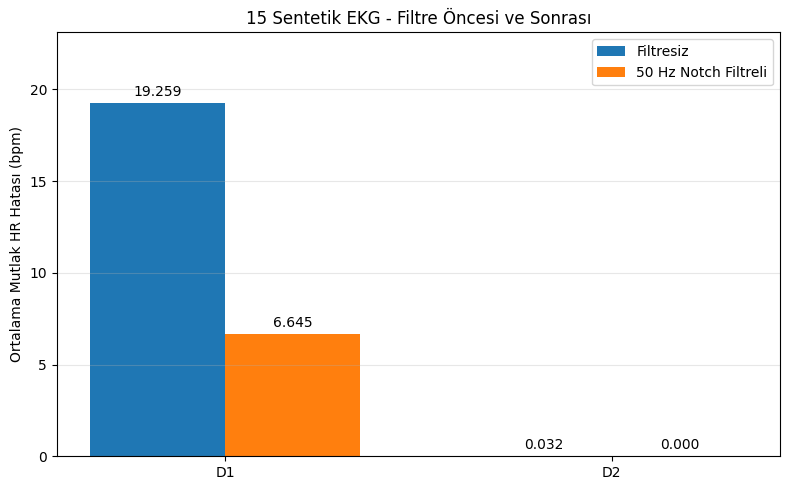

In [16]:

import matplotlib.pyplot as plt

etiketler = ["D1", "D2"]

filtresiz = [
    np.mean(sonuclar[:, 2]),
    np.mean(sonuclar[:, 3])
]

filtreli = [
    np.mean(filtreli_sonuclar[:, 2]),
    np.mean(filtreli_sonuclar[:, 3])
]

konum = np.arange(len(etiketler))
genislik = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

cubuk1 = ax.bar(
    konum - genislik / 2,
    filtresiz,
    genislik,
    label="Filtresiz"
)

cubuk2 = ax.bar(
    konum + genislik / 2,
    filtreli,
    genislik,
    label="50 Hz Notch Filtreli"
)

ax.bar_label(cubuk1, fmt="%.3f", padding=3)
ax.bar_label(cubuk2, fmt="%.3f", padding=3)

ax.set_xticks(konum)
ax.set_xticklabels(etiketler)
ax.set_ylabel("Ortalama Mutlak HR Hatası (bpm)")
ax.set_title("15 Sentetik EKG - Filtre Öncesi ve Sonrası")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(filtresiz + filtreli) * 1.2)

plt.tight_layout()
plt.show()


In [17]:

import sys
import time
import importlib.metadata

bitis_zamani = time.perf_counter()
gecen_sure = bitis_zamani - baslangic_zamani

print("=== ÇALIŞMA BİLGİLERİ ===")
print("Python sürümü:", sys.version.split()[0])
print("NeuroKit2 sürümü:", importlib.metadata.version("neurokit2"))
print("WFDB sürümü:", importlib.metadata.version("wfdb"))
print("Çalışma süresi (saniye):", round(gecen_sure, 2))

print("\n=== ÜRETİLEN DOSYALAR ===")

import os

dosyalar = [
    "sekil1_kesit.png",
    "sekil2_welch.png",
    "tablo_asama2.csv",
    "tablo_asama2_filtreli.csv"
]

for dosya in dosyalar:
    if os.path.isfile(dosya):
        print("HAZIR:", dosya)
    else:
        print("EKSİK:", dosya)


=== ÇALIŞMA BİLGİLERİ ===
Python sürümü: 3.13.16
NeuroKit2 sürümü: 0.2.13
WFDB sürümü: 4.3.1
Çalışma süresi (saniye): 37.14

=== ÜRETİLEN DOSYALAR ===
HAZIR: sekil1_kesit.png
HAZIR: sekil2_welch.png
HAZIR: tablo_asama2.csv
HAZIR: tablo_asama2_filtreli.csv
